**Setup**

In [3]:
from google.colab import drive
drive.mount('/content/drive')

import os, sys, importlib
REPO = "/content/anomaly-mvtec"
if not os.path.exists(REPO):
    !git clone https://github.com/maha-mrrk/anomaly-mvtec.git {REPO}
else:
    !git -C {REPO} pull
%cd {REPO}
if REPO not in sys.path:
    sys.path.append(REPO)
importlib.invalidate_caches()          # prend en compte les nouveaux fichiers après un pull
!pip install -q -r requirements.txt

from src.config import *
set_seed(42)
prepare_data()
print(device, DATA_ROOT)

Mounted at /content/drive
Cloning into '/content/anomaly-mvtec'...
remote: Enumerating objects: 51, done.
remote: Counting objects: 100% (51/51), done.
remote: Compressing objects: 100% (43/43), done.
remote: Total 51 (delta 13), reused 41 (delta 6), pack-reused 0 (from 0)
Receiving objects: 100% (51/51), 5.65 MiB | 33.06 MiB/s, done.
Resolving deltas: 100% (13/13), done.
/content/anomaly-mvtec
Données prêtes : ['carpet', 'screw', 'cable']
cuda /content/mvtec


In [4]:
import torch, numpy as np
from src.data import *
from src.scoring import *
from src.metrics import *

**Cellule 2 : imports et configuration**

In [5]:
import numpy as np, pandas as pd, torch, time
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from src.data import *
from src.scoring import *
from src.metrics import evaluate          # le cadre commun (pas celui du notebook 03)
from src.models.dino import DinoDetector

IMG_SIZE = 224
K_LIST, K_MAIN = [1, 3, 5], 1             # K_MAIN fixé à l'avance ; les autres = ablation
SIGMA = 4
RES_DIR = f"{REPO}/results"; os.makedirs(RES_DIR, exist_ok=True)
det = DinoDetector("dino_vits8", IMG_SIZE, device)

Downloading: "https://github.com/facebookresearch/dino/zipball/main" to /root/.cache/torch/hub/main.zip
Downloading: "https://dl.fbaipublicfiles.com/dino/dino_deitsmall8_pretrain/dino_deitsmall8_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dino_deitsmall8_pretrain.pth


100%|██████████| 82.7M/82.7M [00:00<00:00, 266MB/s]


**Cellule 3 : expériences (3 catégories × 3 valeurs de k)**

In [7]:
rows = {}
for cat in CATEGORIES:
    t0 = time.time()
    tr, val = list_train_val(DATA_ROOT, cat)
    mk = lambda items: MVTecDataset(items, IMG_SIZE, imagenet_norm=True)
    det.fit(DataLoader(mk(tr), batch_size=32, shuffle=False))      # banque = train seul
    test_ds, val_ds = mk(list_test(DATA_ROOT, cat)), mk(val)

    for k in K_LIST:
        maps, labels, masks = predict_maps(lambda x: det.anomaly_map(x, k=k),
                                           test_ds, batch_size=16, device=device)
        res = evaluate(labels, masks, maps, sigma=SIGMA, with_aupro=(k == K_MAIN))
        rows[(cat, k)] = {"model": f"DINO-ViT-S/8_k{k}", "category": cat, **res}
        print(cat, f"k={k}", {a: round(float(b), 3) for a, b in res.items()})
        if k == K_MAIN:
            main_maps = maps
            test_scores = image_scores_from_maps(smooth_maps(maps, SIGMA))

    # scores des images saines de validation : serviront à calibrer le seuil (T9)
    vmaps, _, _ = predict_maps(lambda x: det.anomaly_map(x, k=K_MAIN),
                               val_ds, batch_size=16, device=device)
    val_scores = image_scores_from_maps(smooth_maps(vmaps, SIGMA))
    np.savez_compressed(f"{CKPT_DIR}/dino_scores_{cat}.npz",
                        labels=labels, test_scores=test_scores, val_scores=val_scores)
    print(f"  -> {cat} terminé en {time.time()-t0:.0f}s\n")
    globals()[f"maps_{cat}"] = main_maps        # pour les heatmaps

carpet k=1 {'img_auroc': 0.997, 'pix_auroc': 0.995, 'aupro': 0.981}
carpet k=3 {'img_auroc': 0.998, 'pix_auroc': 0.995}
carpet k=5 {'img_auroc': 0.998, 'pix_auroc': 0.995}
  -> carpet terminé en 79s

screw k=1 {'img_auroc': 0.943, 'pix_auroc': 0.992, 'aupro': 0.964}
screw k=3 {'img_auroc': 0.936, 'pix_auroc': 0.991}
screw k=5 {'img_auroc': 0.931, 'pix_auroc': 0.99}
  -> screw terminé en 87s

cable k=1 {'img_auroc': 0.983, 'pix_auroc': 0.982, 'aupro': 0.942}
cable k=3 {'img_auroc': 0.98, 'pix_auroc': 0.981}
cable k=5 {'img_auroc': 0.978, 'pix_auroc': 0.981}
  -> cable terminé en 87s



**Cellule 4 : tableau et sauvegarde**

In [8]:
df = pd.DataFrame(rows.values())
df.to_csv(f"{RES_DIR}/dino_results.csv", index=False)
df.to_csv(f"{CKPT_DIR}/dino_results.csv", index=False)
df.round(3)

,model,category,img_auroc,pix_auroc,aupro
0,DINO-ViT-S/8_k1,carpet,0.997,0.995,0.981
1,DINO-ViT-S/8_k3,carpet,0.998,0.995,NaN
2,DINO-ViT-S/8_k5,carpet,0.998,0.995,NaN
3,DINO-ViT-S/8_k1,screw,0.943,0.992,0.964
4,DINO-ViT-S/8_k3,screw,0.936,0.991,NaN
5,DINO-ViT-S/8_k5,screw,0.931,0.990,NaN
6,DINO-ViT-S/8_k1,cable,0.983,0.982,0.942
7,DINO-ViT-S/8_k3,cable,0.980,0.981,NaN
8,DINO-ViT-S/8_k5,cable,0.978,0.981,NaN


**Cellule 5 : heatmaps**

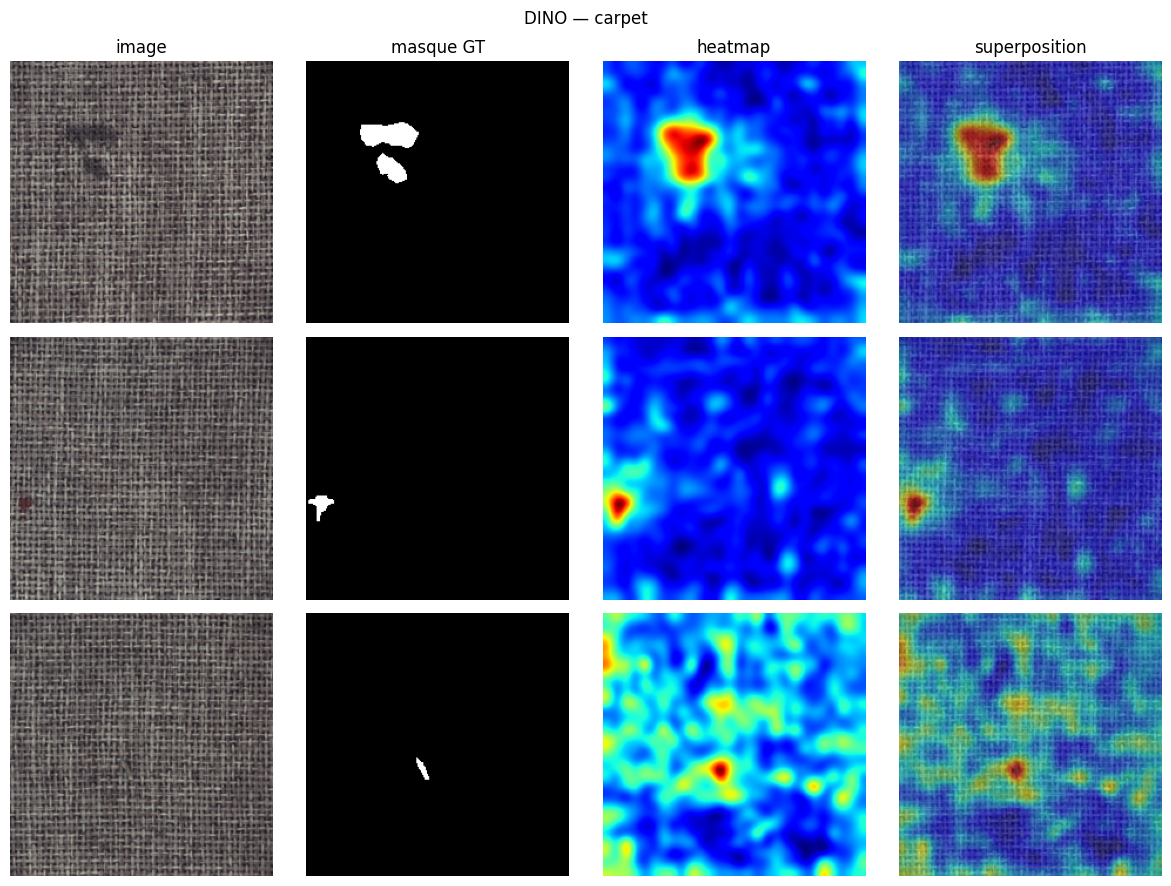

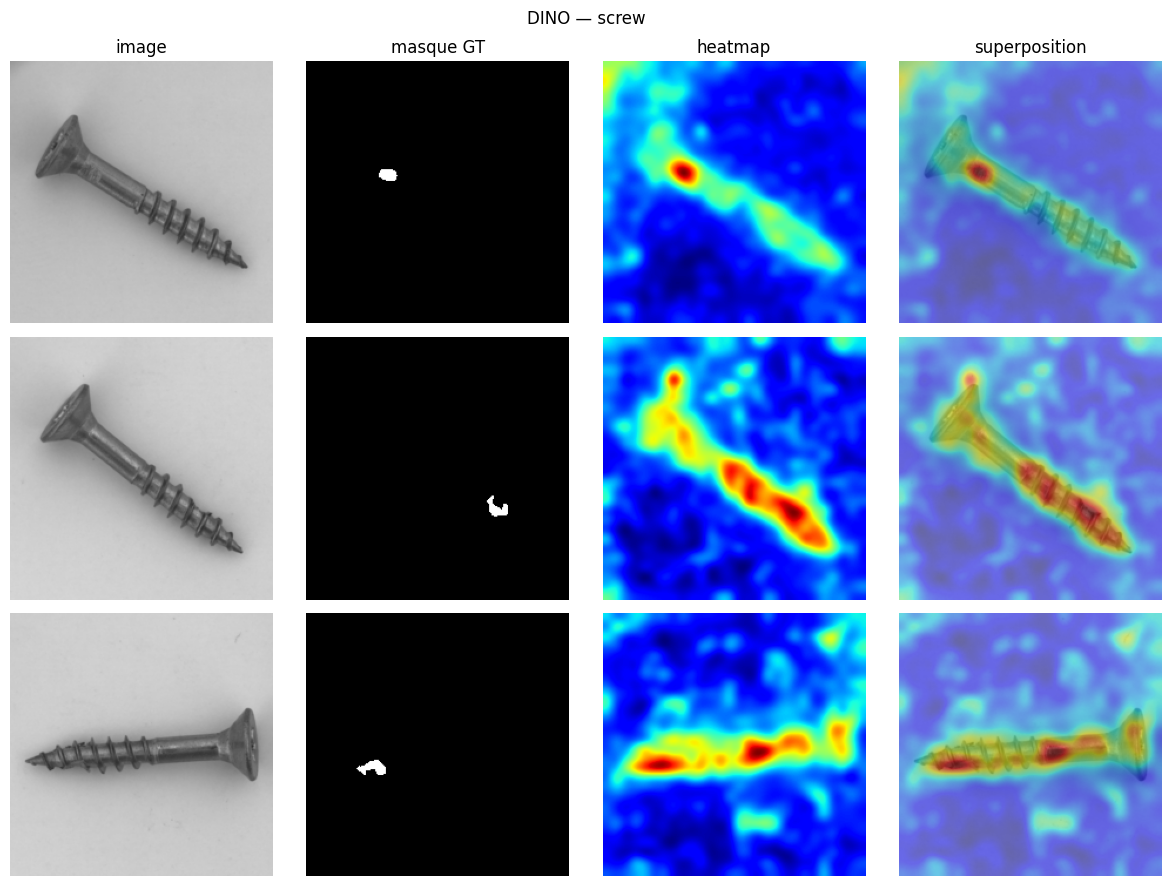

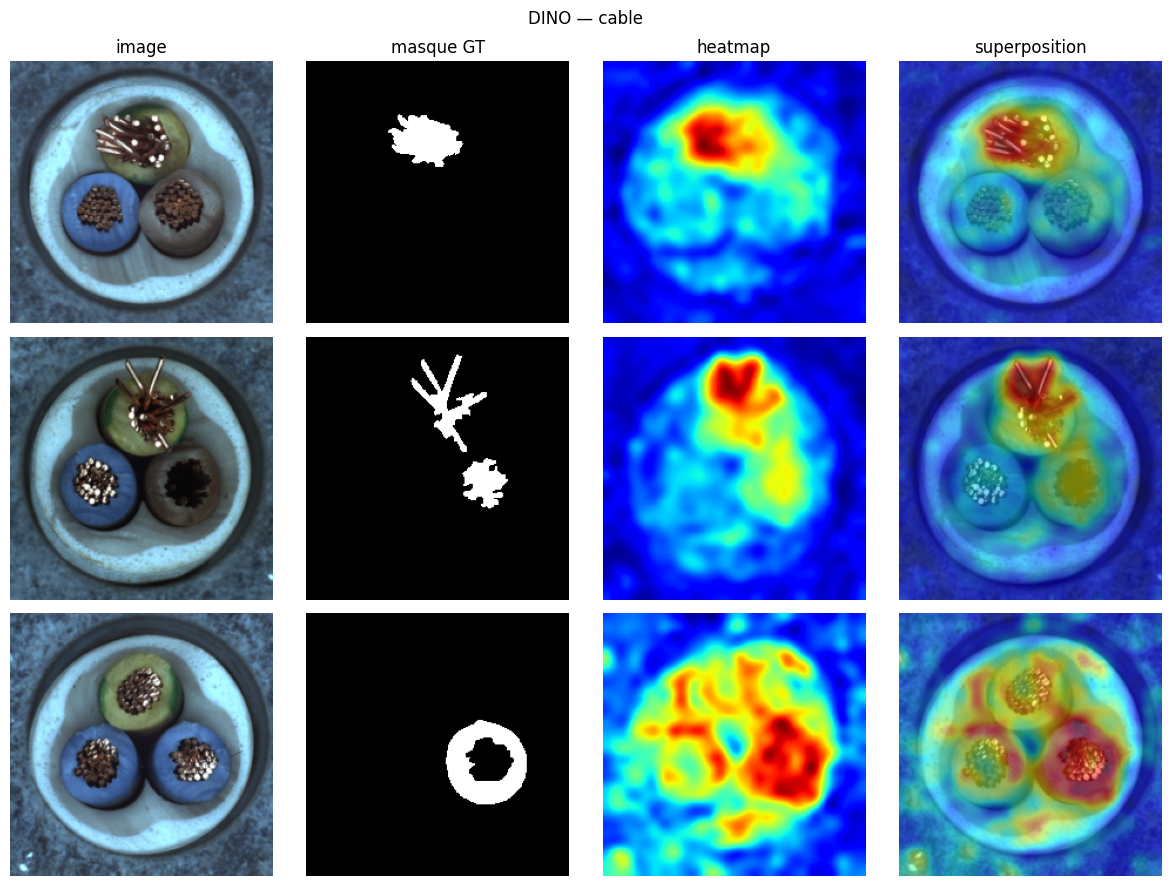

In [9]:
def show_examples(cat, maps, n=3):
    ds = MVTecDataset(list_test(DATA_ROOT, cat), IMG_SIZE)          # sans normalisation, pour l'affichage
    labels = np.array([l for _, l, _ in ds.items])
    idx = np.random.RandomState(0).choice(np.where(labels == 1)[0], n, replace=False)
    sm = smooth_maps(maps, SIGMA)
    fig, ax = plt.subplots(n, 4, figsize=(12, 3 * n))
    for r, i in enumerate(idx):
        img, _, m = ds[i]; img = img.permute(1, 2, 0).numpy()
        ax[r, 0].imshow(img); ax[r, 1].imshow(m[0], cmap="gray")
        ax[r, 2].imshow(sm[i], cmap="jet")
        ax[r, 3].imshow(img); ax[r, 3].imshow(sm[i], cmap="jet", alpha=0.5)
        for a in ax[r]: a.axis("off")
    for a, t in zip(ax[0], ["image", "masque GT", "heatmap", "superposition"]): a.set_title(t)
    plt.suptitle(f"DINO — {cat}"); plt.tight_layout()
    plt.savefig(f"{RES_DIR}/dino_examples_{cat}.png", dpi=150); plt.show()

for cat in CATEGORIES:
    show_examples(cat, globals()[f"maps_{cat}"])

In [10]:
%cd /content/anomaly-mvtec
!zip /content/results04.zip results/dino_*
from google.colab import files
files.download("/content/results04.zip")

/content/anomaly-mvtec
  adding: results/dino_examples_cable.png (deflated 1%)
  adding: results/dino_examples_carpet.png (deflated 0%)
  adding: results/dino_examples_screw.png (deflated 1%)
  adding: results/dino_results.csv (deflated 54%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>